# 01 · Data Quality & Store KPI Monitoring

**Goal:** validate the raw exports, then build the weekly KPI report the business uses
to track traffic (UV / PV), conversion and revenue.

*All data is synthetic — see the project README.*

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

import db
import plot_style as ps

ps.apply()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
con = db.connect()

## 1. Data-quality checks (`sql/01_data_quality.sql`)

In [2]:
dq = db.run(con, "01_data_quality")
dq

,check_name,issues
0,behavior: exact duplicate rows,800
1,customers: missing gender,798
2,orders: refunded (excluded from revenue KPIs),604
3,orders: net_amount <= 0,0
4,orders: customer not in customers table,0
5,ads: campaign-days with spend > 0 but 0 clicks,1


**Handling decisions**
- **Duplicate behaviour rows** come from logging retries → removed (the `behavior` view uses `SELECT DISTINCT`).
- **Missing gender (~5%)** → kept; gender is not used as a model feature.
- **Refunded orders** → excluded from GMV / order KPIs.
- **One campaign-day with spend but zero clicks** → a click-tracking outage, investigated in notebook 02.

## 2. Weekly KPI report (`sql/02_weekly_store_kpis.sql`)

In [3]:
weekly = db.run(con, "02_weekly_store_kpis")
weekly["week"] = pd.to_datetime(weekly["week"])
weekly.tail(8)

,week,uv,pv,visits,add_to_cart,orders,buyers,gmv,conversion_rate_pct,aov,coupon_rate_pct,uv_wow_pct,gmv_wow_pct
34,2023-10-02,6272,39813.0,9039,1337.0,825,772,113793.0,12.31,137.9,33.2,1.7,-1.8
35,2023-10-09,6294,39890.0,9125,1364.0,807,746,113337.0,11.85,140.4,29.5,0.4,-0.4
36,2023-10-16,6316,40187.0,9166,1341.0,776,710,110471.0,11.24,142.4,31.3,0.3,-2.5
37,2023-10-23,9318,74761.0,17418,2624.0,2923,2389,285165.0,25.64,97.6,73.4,47.5,158.1
38,2023-10-30,9539,78877.0,18563,2946.0,3388,2702,321876.0,28.33,95.0,75.9,2.4,12.9
39,2023-11-06,10697,94639.0,22308,3472.0,3823,3000,370709.0,28.05,97.0,74.4,12.1,15.2
40,2023-11-13,6436,40568.0,9303,1359.0,897,841,126790.0,13.07,141.3,31.4,-39.8,-65.8
41,2023-11-20,6326,40245.0,9207,1429.0,864,794,121348.0,12.55,140.4,30.4,-1.7,-4.3


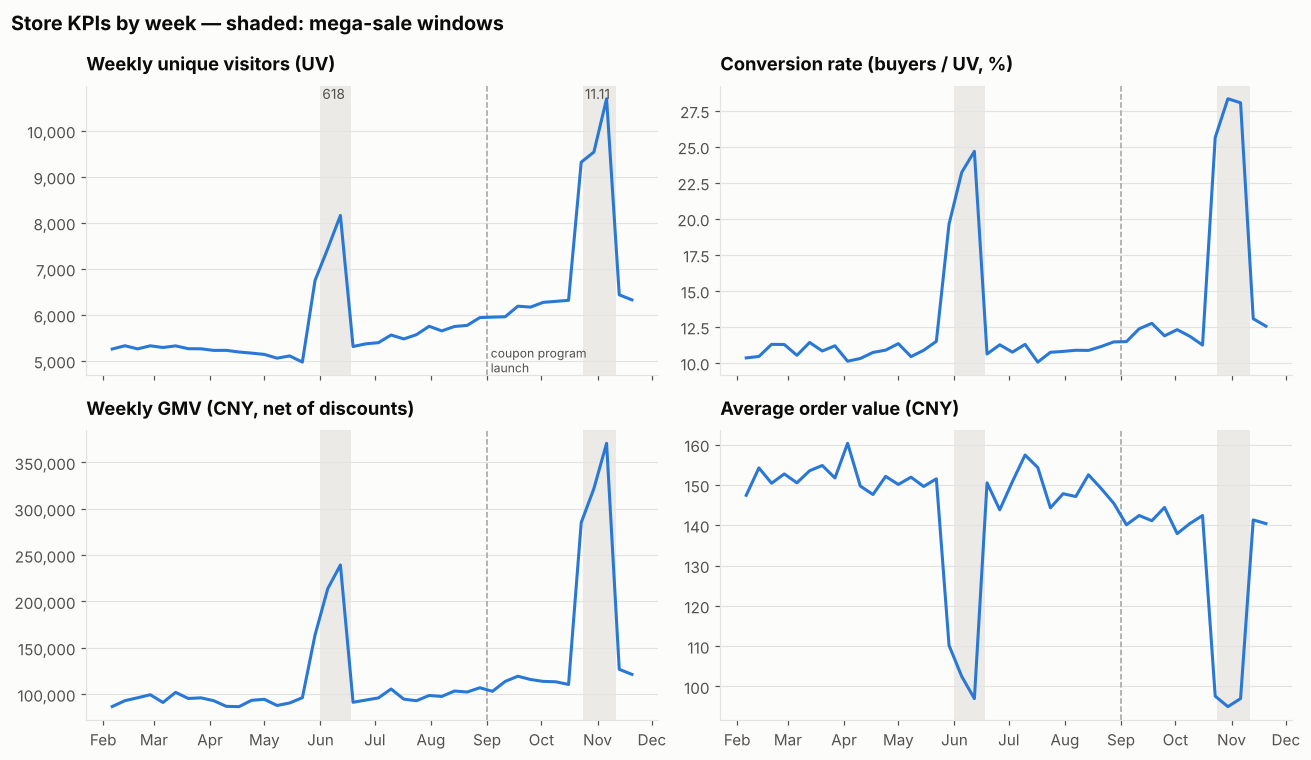

In [4]:
EVENTS = [
    ("618 sale", "2023-06-01", "2023-06-18"),
    ("Singles' Day", "2023-10-24", "2023-11-11"),
]
PROGRAM = pd.Timestamp("2023-09-01")

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
panels = [
    ("uv", "Weekly unique visitors (UV)", "{:,.0f}"),
    ("conversion_rate_pct", "Conversion rate (buyers / UV, %)", "{:.1f}"),
    ("gmv", "Weekly GMV (CNY, net of discounts)", "{:,.0f}"),
    ("aov", "Average order value (CNY)", "{:.0f}"),
]
for ax, (col, title, fmt) in zip(axes.flat, panels):
    for _, a, b in EVENTS:
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=ps.GRID, alpha=0.7, lw=0)
    ax.axvline(PROGRAM, color=ps.CONTEXT, lw=1, ls="--")
    ax.plot(weekly["week"], weekly[col], color=ps.BLUE)
    ax.set_title(title)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _, f=fmt: f.format(v)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
axes[0, 0].text(pd.Timestamp("2023-06-02"), axes[0, 0].get_ylim()[1], "618", va="top", color=ps.TEXT_2, fontsize=9)
axes[0, 0].text(pd.Timestamp("2023-10-25"), axes[0, 0].get_ylim()[1], "11.11", va="top", color=ps.TEXT_2, fontsize=9)
axes[0, 0].text(PROGRAM + pd.Timedelta(days=2), axes[0, 0].get_ylim()[0], "coupon program\nlaunch", va="bottom",
                color=ps.TEXT_2, fontsize=8)
fig.suptitle("Store KPIs by week — shaded: mega-sale windows", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
ps.save(fig, "01_weekly_kpis")

## 3. Monthly summary

In [5]:
monthly = con.execute("""
    WITH t AS (SELECT DATE_TRUNC('month', date) m, COUNT(DISTINCT customer_id) uv, SUM(page_views) pv
               FROM behavior GROUP BY 1),
         s AS (SELECT DATE_TRUNC('month', order_date) m, COUNT(*) orders, COUNT(DISTINCT customer_id) buyers,
                      SUM(net_amount) gmv
               FROM orders WHERE order_status = 'completed' GROUP BY 1)
    SELECT strftime(m, '%Y-%m') AS month, uv, pv, orders, buyers,
           ROUND(buyers * 100.0 / uv, 1) AS conversion_rate_pct,
           ROUND(gmv, 0) AS gmv, ROUND(gmv / orders, 1) AS aov
    FROM t JOIN s USING (m) ORDER BY m
""").df()
monthly

,month,uv,pv,orders,buyers,conversion_rate_pct,gmv,aov
0,2023-02,9651,130885.0,2450,1914,19.8,371769.0,151.7
1,2023-03,10011,146542.0,2799,2082,20.8,427977.0,152.9
2,2023-04,9714,141915.0,2555,1928,19.8,389145.0,152.3
3,2023-05,9501,144695.0,2698,1972,20.8,408062.0,151.2
4,2023-06,10379,219603.0,6828,4213,40.6,729942.0,106.9
5,2023-07,10193,157840.0,2875,2134,20.9,435790.0,151.6
6,2023-08,10623,162734.0,2995,2251,21.2,445133.0,148.6
7,2023-09,11020,163785.0,3405,2552,23.2,484865.0,142.4
8,2023-10,12137,222320.0,6355,4288,35.3,727159.0,114.4
9,2023-11,12482,255285.0,8558,5242,42.0,924018.0,108.0


## 4. Conversion by traffic source
Which channels bring visitors who actually buy?

In [6]:
by_source = con.execute("""
    SELECT traffic_source,
           COUNT(*) AS visits,
           SUM(add_to_cart) * 100.0 / COUNT(*) AS add_to_cart_rate_pct,
           SUM(orders) * 100.0 / COUNT(*)      AS visit_to_order_pct
    FROM behavior
    GROUP BY 1 ORDER BY visit_to_order_pct
""").df().round(2)
by_source

,traffic_source,visits,add_to_cart_rate_pct,visit_to_order_pct
0,Recommendation Feed,125854,13.31,7.40
1,Display Ads,56061,14.43,8.77
2,Organic Search,81105,14.63,9.89
3,Paid Search,50749,15.23,11.27
4,Livestream/Influencer,34747,17.06,12.73
5,Favorites/Direct,51445,16.22,18.91


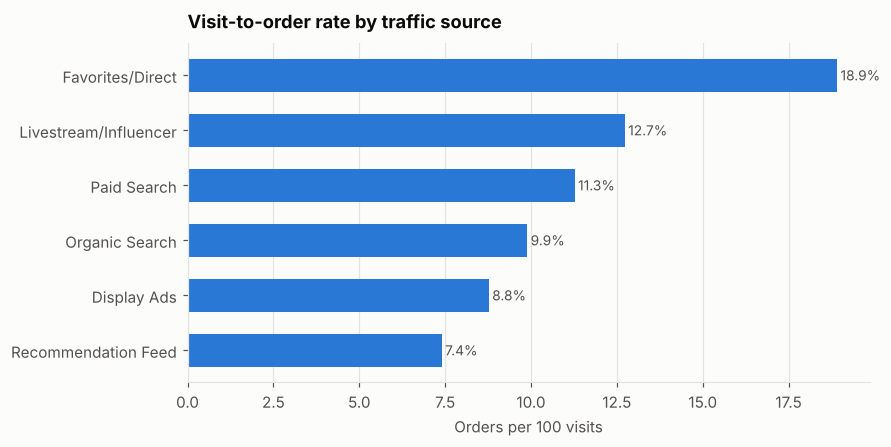

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(by_source["traffic_source"], by_source["visit_to_order_pct"], color=ps.BLUE, height=0.6)
for y, v in enumerate(by_source["visit_to_order_pct"]):
    ax.text(v + 0.1, y, f"{v:.1f}%", va="center", color=ps.TEXT_2, fontsize=9)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("Orders per 100 visits")
ax.set_title("Visit-to-order rate by traffic source")
ps.save(fig, "01_conversion_by_source")

## Takeaways
- Traffic and GMV are driven by the two **mega-sales**: GMV in the 618 and Singles' Day weeks is far above the
  normal weekly run-rate, so week-over-week alerts must be read against the promo calendar.
- **Favorites/Direct** visitors (returning customers) convert best; **Recommendation Feed** brings a lot of
  visits but converts worst — a candidate for better targeting.
- GMV in Sep–Nov is up versus the summer months even outside Singles' Day; notebook 04 tests how much of
  that comes from the coupon program.